# IMPORTS

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import xgboost as xgb
import numpy as np
import seaborn as sns
import pandas as pd

DATA_DIR = Path("FRED")
RESULTS_PATH = Path("results/dl_models_results.json")
TRAIN_FRACTION = 0.8
VALIDATION_FRACTION = 0.1
model_results = {}

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Using device: {DEVICE}")

Using device: cuda


# DATA LOADING

In [2]:
def load_data(file_name, BASE_DIR=DATA_DIR):
    file_path = BASE_DIR / file_name
    data = pd.read_csv(file_path)
    return data

### LOAD THE DATA

In [3]:
usdinr = load_data("DEXINUS.csv")
usdjpy = load_data("DEXJPUS.csv")
usdeur = load_data("DEXUSEU.csv")
repo_rate = load_data("DFF.csv")
treasury_yield = load_data("DGS10.csv")
commodity_prices = load_data("commodity_futures.csv")
india_vix = load_data("VIX_History.csv")
nifty50 = load_data("NIFTY 50_Data.csv")
nifty50pepb = load_data("NIFTY 50 - HistoricalPE_PBDIV_Data.csv")
niftybank = load_data("NIFTY BANK_Data.csv")
niftybankpepb = load_data("NIFTY BANK - HistoricalPE_PBDIV_Data.csv")
india_gold = load_data("Gold price INR.csv")
sap500 = load_data("sap500.csv")

### BASIC EXPLORATION

In [4]:
print("USD/INR Data:")
print(usdinr.head())
print("USD/JPY Data:")
print(usdjpy.head())
print("USD/EUR Data:")
print(usdeur.head())
print("Repo Rate Data:")
print(repo_rate.head())
print("Treasury Yield Data:")
print(treasury_yield.head())
print("Commodity Prices Data:")
print(commodity_prices.head())
print("India VIX Data:")
print(india_vix.head())
print("Nifty 50 Data:")
print(nifty50.head())
print("Nifty Bank Data:")
print(niftybank.head())
print("S&P 500 Data:")
print(sap500.head())

USD/INR Data:
  observation_date  DEXINUS
0       1973-01-02     8.02
1       1973-01-03     8.02
2       1973-01-04     8.00
3       1973-01-05     8.01
4       1973-01-08     8.00
USD/JPY Data:
  observation_date  DEXJPUS
0       1971-01-04   357.73
1       1971-01-05   357.81
2       1971-01-06   357.86
3       1971-01-07   357.87
4       1971-01-08   357.82
USD/EUR Data:
  observation_date  DEXUSEU
0       1999-01-04   1.1812
1       1999-01-05   1.1760
2       1999-01-06   1.1636
3       1999-01-07   1.1672
4       1999-01-08   1.1554
Repo Rate Data:
  observation_date   DFF
0       1954-07-01  1.13
1       1954-07-02  1.25
2       1954-07-03  1.25
3       1954-07-04  1.25
4       1954-07-05  0.88
Treasury Yield Data:
  observation_date  DGS10
0       1962-01-02   4.06
1       1962-01-03   4.03
2       1962-01-04   3.99
3       1962-01-05   4.02
4       1962-01-08   4.03
Commodity Prices Data:
         Date  NATURAL GAS   GOLD  WTI CRUDE  BRENT CRUDE  SOYBEANS    CORN  \
0  2000-0

In [5]:
print("\033[1;32m" + "="*30 + " USD/INR Data: " + "="*30 + "\033[0m")
print(usdinr.info())
print(usdinr.describe())
print("\033[1;32m" + "="*30 + " USD/JPY Data: " + "="*30 + "\033[0m")
print(usdjpy.info())
print(usdjpy.describe())
print("\033[1;32m" + "="*30 + " USD/EUR Data: " + "="*30 + "\033[0m")
print(usdeur.info())
print(usdeur.describe())
print("\033[1;32m" + "="*30 + " Repo Rate Data: " + "="*30 + "\033[0m")
print(repo_rate.info())
print(repo_rate.describe())
print("\033[1;32m" + "="*30 + " Treasury Yield Data: " + "="*30 + "\033[0m")
print(treasury_yield.info())
print(treasury_yield.describe())
print("\033[1;32m" + "="*30 + " Commodity Prices Data: " + "="*30 + "\033[0m")
print(commodity_prices.info())
print(commodity_prices.describe())
print("\033[1;32m" + "="*30 + " India VIX Data: " + "="*30 + "\033[0m")
print(india_vix.info())
print(india_vix.describe())
print("\033[1;32m" + "="*30 + " Nifty 50 Data: " + "="*30 + "\033[0m")
print(nifty50.info())
print(nifty50.describe())
print("\033[1;32m" + "="*30 + " Nifty Bank Data: " + "="*30 + "\033[0m")
print(niftybank.info())
print(niftybank.describe())
print("\033[1;32m" + "="*30 + " S&P 500 Data: " + "="*30 + "\033[0m")
print(sap500.info())
print(sap500.describe())

============================== USD/INR Data: ==============================
<class 'pandas.DataFrame'>
RangeIndex: 13999 entries, 0 to 13998
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  13999 non-null  str    
 1   DEXINUS           13449 non-null  float64
dtypes: float64(1), str(1)
memory usage: 355.6 KB
None
            DEXINUS
count  13449.000000
mean      38.951964
std       24.830751
min        7.190000
25%       12.620000
50%       42.500000
75%       55.520000
max       96.820000
============================== USD/JPY Data: ==============================
<class 'pandas.DataFrame'>
RangeIndex: 14520 entries, 0 to 14519
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  14520 non-null  str    
 1   DEXJPUS           13951 non-null  float64
dtypes: float64(1), str(1)
memory usage: 36

### ADD INDEXES

### SET INDEXES

In [6]:
usdinr["observation_date"] = pd.to_datetime(usdinr["observation_date"])
usdinr = usdinr.set_index("observation_date")

usdjpy["observation_date"] = pd.to_datetime(usdjpy["observation_date"])
usdjpy = usdjpy.set_index("observation_date")

usdeur["observation_date"] = pd.to_datetime(usdeur["observation_date"])
usdeur = usdeur.set_index("observation_date")

repo_rate["observation_date"] = pd.to_datetime(repo_rate["observation_date"])
repo_rate = repo_rate.set_index("observation_date")

treasury_yield["observation_date"] = pd.to_datetime(treasury_yield["observation_date"])
treasury_yield = treasury_yield.set_index("observation_date")

commodity_prices["Date"] = pd.to_datetime(commodity_prices["Date"])
commodity_prices = commodity_prices.set_index("Date")

india_vix["Date"] = pd.to_datetime(india_vix["DATE"])
india_vix = india_vix.set_index("Date")

nifty50["Date"] = pd.to_datetime(nifty50["Date"])
nifty50 = nifty50.set_index("Date")

nifty50pepb["Date"] = pd.to_datetime(nifty50pepb["Date"])
nifty50pepb = nifty50pepb.set_index("Date")

niftybank["Date"] = pd.to_datetime(niftybank["Date"])
niftybank = niftybank.set_index("Date")

niftybankpepb["Date"] = pd.to_datetime(niftybankpepb["Date"])
niftybankpepb = niftybankpepb.set_index("Date")

india_gold["Date"] = pd.to_datetime(india_gold["Date"], format="%d/%m/%Y")
india_gold = india_gold.set_index("Date")

sap500["Date"] = pd.to_datetime(sap500["Date"])
sap500 = sap500.set_index("Date")

### MERGE INDEXES AND DATAFRAMES AND ADD FEATURES

In [7]:
## MERGE INDEXES AND DATAFRAMES

# USDINR
full_df = usdinr.copy()

# GLOBAL DATA
full_df["jpy"] = usdjpy["DEXJPUS"]
full_df["eur"] = usdeur["DEXUSEU"]
full_df["repo_rate"] = repo_rate["DFF"]
full_df["treasury_yield"] = treasury_yield["DGS10"]

# COMMODITY PRICES GLOBALLY
full_df["gold"] = commodity_prices["GOLD"]
full_df["wti_crude"] = commodity_prices["WTI CRUDE"]
full_df["brent_crude"] = commodity_prices["BRENT CRUDE"]
full_df["soybeans"] = commodity_prices["SOYBEANS"]
full_df["corn"] = commodity_prices["CORN"]
full_df["copper"] = commodity_prices["COPPER"]
full_df["silver"] = commodity_prices["SILVER"]
full_df["low_sulphur_gas_oil"] = commodity_prices["LOW SULPHUR GAS OIL"]
full_df["live_cattle"] = commodity_prices["LIVE CATTLE"]
full_df["soybean_oil"] = commodity_prices["SOYBEAN OIL"]
full_df["aluminium"] = commodity_prices["ALUMINIUM"]
full_df["soybean_meal"] = commodity_prices["SOYBEAN MEAL"]
full_df["zinc"] = commodity_prices["ZINC"]
full_df["uls_diesel"] = commodity_prices["ULS DIESEL"]
full_df["nickel"] = commodity_prices["NICKEL"]
full_df["wheat"] = commodity_prices["WHEAT"]
full_df["sugar"] = commodity_prices["SUGAR"]
# full_df["gasoline"] = commodity_prices["GASOLINE"]
full_df["coffee"] = commodity_prices["COFFEE"]
full_df["lean_hogs"] = commodity_prices["LEAN HOGS"]
full_df["hrw_wheat"] = commodity_prices["HRW WHEAT"]
full_df["cotton"] = commodity_prices["COTTON"]

# INDIA DATA
full_df["india_vix_open"] = india_vix["OPEN"]
full_df["india_vix_high"] = india_vix["HIGH"]
full_df["india_vix_low"] = india_vix["LOW"]
full_df["india_vix_close"] = india_vix["CLOSE"]
full_df["nifty50_open"] = nifty50["Open"]
full_df["nifty50_high"] = nifty50["High"]
full_df["nifty50_low"] = nifty50["Low"]
full_df["nifty50_close"] = nifty50["Close"]
full_df["nifty50_pe"] = nifty50pepb["P/E"]
full_df["nifty50_pb"] = nifty50pepb["P/B"]
full_df["nifty50_div_yield"] = nifty50pepb["Div Yield %"]
# full_df["niftybank_open"] = niftybank["Open"]
# full_df["niftybank_high"] = niftybank["High"]
# full_df["niftybank_low"] = niftybank["Low"]
full_df["niftybank_close"] = niftybank["Close"]
full_df["niftybank_pe"] = niftybankpepb["P/E"]
full_df["niftybank_pb"] = niftybankpepb["P/B"]
full_df["niftybank_div_yield"] = niftybankpepb["Div Yield %"]
full_df["india_gold"] = india_gold["INR"]

# US DATA
full_df["sp500_open"] = sap500["Open"]
full_df["sp500_high"] = sap500["High"]
full_df["sp500_low"] = sap500["Low"]
full_df["sp500_close"] = sap500["Close"]
full_df["sp500_volume"] = sap500["Volume"]

print(full_df.head())


                  DEXINUS     jpy  eur  repo_rate  treasury_yield  gold  \
observation_date                                                          
1973-01-02           8.02  301.39  NaN       6.00            6.43   NaN   
1973-01-03           8.02  301.43  NaN       5.50            6.42   NaN   
1973-01-04           8.00  301.20  NaN       5.75            6.40   NaN   
1973-01-05           8.01  301.30  NaN       5.75            6.42   NaN   
1973-01-08           8.00  302.21  NaN       5.63            6.43   NaN   

                  wti_crude  brent_crude  soybeans  corn  ...  \
observation_date                                          ...   
1973-01-02              NaN          NaN       NaN   NaN  ...   
1973-01-03              NaN          NaN       NaN   NaN  ...   
1973-01-04              NaN          NaN       NaN   NaN  ...   
1973-01-05              NaN          NaN       NaN   NaN  ...   
1973-01-08              NaN          NaN       NaN   NaN  ...   

                  

### GARCH FEATURES

In [8]:
from arch import arch_model

### DATA CLEANING

In [9]:
# Keep observations from 1 January 2000 onward before handling missing values.
full_df = full_df.loc[
    full_df.index.to_series().between("2000-01-01", "2021-12-31")
].copy()

print(f"Shape after restricting data to 2000 onward: {full_df.shape}")
missing_summary = (
    full_df.isna()
    .sum()
    .sort_values(ascending=False)
    .rename("missing_values")
    .to_frame()
    .assign(
        missing_percent=lambda frame: (
            frame["missing_values"] / len(full_df) * 100
        ).round(2)
    )
)
missing_summary = missing_summary[missing_summary["missing_values"] > 0]

print("Columns with missing values:")
display(missing_summary)

Shape after restricting data to 2000 onward: (5740, 47)
Columns with missing values:


,missing_values,missing_percent
niftybank_pb,291,5.07
nifty50_pe,291,5.07
niftybank_pe,291,5.07
niftybank_div_yield,291,5.07
nifty50_pb,291,5.07
nifty50_div_yield,291,5.07
nifty50_open,290,5.05
nifty50_close,290,5.05
nifty50_high,290,5.05
niftybank_close,290,5.05


<Axes: title={'center': 'India VIX Close Price Over Time'}, xlabel='observation_date'>

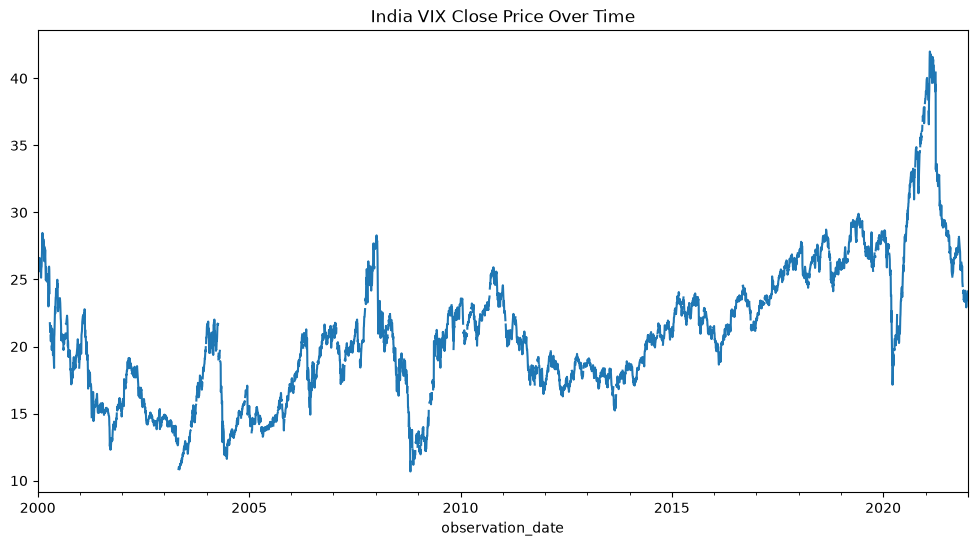

In [10]:
full_df["nifty50_pe"].plot(figsize=(12, 6), title="India VIX Close Price Over Time")

In [11]:
missing_dates = full_df.index[full_df.isna().any(axis=1)]

missing_date_analysis = pd.DataFrame(index=missing_dates)
missing_date_analysis["day_name"] = missing_date_analysis.index.day_name()
missing_date_analysis["is_weekend"] = (
    missing_date_analysis.index.dayofweek >= 5
)

print("Missing dates:", len(missing_date_analysis))
print("\nMissing dates by weekday:")
display(missing_date_analysis["day_name"].value_counts())

print("\nWeekend missing dates:")
print(missing_date_analysis["is_weekend"].sum())

print("\nMissing dates by month:")
display(missing_date_analysis.index.month.value_counts().sort_index())

Missing dates: 504

Missing dates by weekday:


day_name
Monday       189
Friday        97
Thursday      89
Wednesday     65
Tuesday       64
Name: count, dtype: int64


Weekend missing dates:
0

Missing dates by month:


observation_date
1     65
2     34
3     36
4     52
5     42
6      3
7     26
8     25
9     43
10    69
11    74
12    35
Name: count, dtype: int64

In [12]:
missing_dates = pd.Series(
    full_df.index[full_df.isna().any(axis=1)]
).sort_values()

missing_date_gaps = missing_dates.diff().dt.days

print("Largest gaps between missing dates:")
display(missing_date_gaps.sort_values(ascending=False).head(20))

Largest gaps between missing dates:


468    66.0
206    66.0
346    66.0
94     63.0
229    63.0
227    47.0
109    46.0
16     45.0
28     42.0
178    42.0
158    42.0
137    42.0
414    42.0
52     42.0
11     42.0
247    42.0
270    42.0
74     42.0
394    42.0
242    41.0
Name: observation_date, dtype: float64

In [13]:
full_df = full_df.sort_index()

target_col = "DEXINUS"  # USD/INR target
feature_cols = full_df.columns.difference([target_col])

# Carry forward the last known market value for short calendar gaps.
# limit=5 prevents filling across long missing periods.
full_df[feature_cols] = full_df[feature_cols].ffill(limit=5)

# Never fabricate the target value.
full_df = full_df.dropna(subset=[target_col])

# Remove rows where a feature has a long/unresolved gap.
full_df = full_df.dropna(subset=feature_cols)

print(full_df.isna().sum().sum())
print(full_df.shape)

0
(5516, 47)


### MORE FEATURES

In [14]:
# Technical Indicators
full_df["usdinr_ma_5"] = full_df["DEXINUS"].rolling(window=5, min_periods=1).mean()
full_df["usdinr_ma_10"] = full_df["DEXINUS"].rolling(window=10, min_periods=1).mean()
full_df["usdinr_ma_30"] = full_df["DEXINUS"].rolling(window=30, min_periods=1).mean()
full_df["usdinr_ma_50"] = full_df["DEXINUS"].rolling(window=50, min_periods=1).mean()
full_df["usdinr_ma_100"] = full_df["DEXINUS"].rolling(window=100, min_periods=1).mean()
full_df["usdinr_ema_5"] = full_df["DEXINUS"].ewm(span=5, adjust=False).mean()
full_df["usdinr_ema_10"] = full_df["DEXINUS"].ewm(span=10, adjust=False).mean()
full_df["usdinr_ema_30"] = full_df["DEXINUS"].ewm(span=30, adjust=False).mean()
full_df["usdinr_ema_50"] = full_df["DEXINUS"].ewm(span=50, adjust=False).mean()
full_df["usdinr_ema_100"] = full_df["DEXINUS"].ewm(span=100, adjust=False).mean()
full_df["returns"] = full_df["DEXINUS"].pct_change()
full_df["returns_5day"] = full_df["returns"].rolling(window=5, min_periods=1).mean()
full_df["returns_10day"] = full_df["returns"].rolling(window=10, min_periods=1).mean()
full_df["log_returns"] = np.log(full_df["DEXINUS"] / full_df["DEXINUS"].shift(1))
full_df["log_returns_5day"] = full_df["log_returns"].rolling(window=5, min_periods=1).mean()
full_df["volatility_5day"] = full_df["log_returns"].rolling(window=5, min_periods=1).std()

### FINAL CLEANING

In [15]:
# Keep observations from 1 January 2000 onward before handling missing values.
full_df = full_df.loc[
    full_df.index.to_series().between("2000-01-01", "2021-12-31")
].copy()

print(f"Shape after restricting data to 2000 onward: {full_df.shape}")
missing_summary = (
    full_df.isna()
    .sum()
    .sort_values(ascending=False)
    .rename("missing_values")
    .to_frame()
    .assign(
        missing_percent=lambda frame: (
            frame["missing_values"] / len(full_df) * 100
        ).round(2)
    )
)
missing_summary = missing_summary[missing_summary["missing_values"] > 0]

print("Columns with missing values:")
display(missing_summary)

Shape after restricting data to 2000 onward: (5516, 63)
Columns with missing values:


,missing_values,missing_percent
volatility_5day,2,0.04
returns_5day,1,0.02
log_returns,1,0.02
log_returns_5day,1,0.02
returns,1,0.02
returns_10day,1,0.02


In [16]:
# Final cleaning after all technical features have been created.
full_df = full_df.loc[
    full_df.index.to_series().between("2000-01-01", "2021-12-31")
].sort_index().copy()

# Convert placeholder strings before filling and dropping missing values.
numeric_columns = [
    "nifty50_div_yield",
    "niftybank_div_yield",
    "niftybank_pe",
]
for column in numeric_columns:
    full_df[column] = pd.to_numeric(
        full_df[column].replace({"-": np.nan, "": np.nan}),
        errors="coerce",
    )

# Predict today's log return using information available through the previous day.
target_col = "log_returns"
feature_cols = full_df.columns.difference([target_col])
full_df[feature_cols] = full_df[feature_cols].ffill(limit=5)
full_df[feature_cols] = full_df[feature_cols].shift(1)

# Do not fill the target or use future observations to create features.
full_df = full_df.dropna(subset=[target_col])
full_df = full_df.dropna(subset=feature_cols)
feature_cols = full_df.columns.difference([target_col])

print(f"Target column: {target_col}")
print(f"Shape after final cleaning: {full_df.shape}")
print(f"Remaining missing values: {int(full_df.isna().sum().sum())}")


Target column: log_returns
Shape after final cleaning: (5513, 63)
Remaining missing values: 0


### ADD GARCH FEATURES

In [17]:
# GARCH-based volatility features
returns = (full_df["log_returns"] * 100).dropna()

models = {
    "garch": arch_model(returns, mean="Constant", vol="GARCH", p=1, q=1, dist="t").fit(disp="off"),
    "egarch": arch_model(returns, mean="Constant", vol="EGARCH", p=1, o=1, q=1, dist="t").fit(disp="off"),
    "figarch": arch_model(returns, mean="Constant", vol="FIGARCH", p=1, q=1, dist="t").fit(disp="off"),
    "aparch": arch_model(returns, mean="Constant", vol="APARCH", p=1, o=1, q=1, dist="t").fit(disp="off"),
}

for model_name, model in models.items():
    full_df[f"garch_{model_name}_volatility"] = (
        model.conditional_volatility / 100
    ).reindex(full_df.index).shift(1)

feature_cols = full_df.columns.difference([target_col])
full_df = full_df.dropna(subset=feature_cols)
feature_cols = full_df.columns.difference([target_col])
print("GARCH features added:")
print([column for column in feature_cols if column.startswith("garch_")])


GARCH features added:
['garch_aparch_volatility', 'garch_egarch_volatility', 'garch_figarch_volatility', 'garch_garch_volatility']


### COORELATION MATRIX

<Axes: >

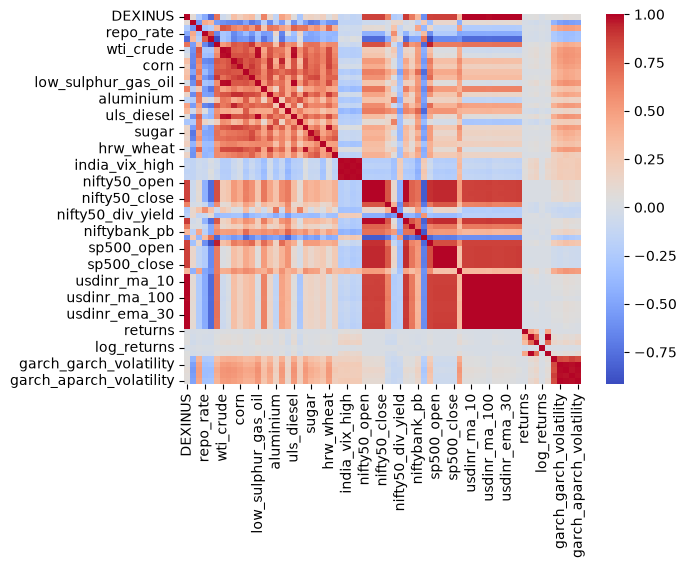

In [18]:
# CORRELATION ANALYSIS
correlation_matrix = full_df.corr()
sns.heatmap(correlation_matrix, fmt=".2f", cmap="coolwarm", cbar=True)

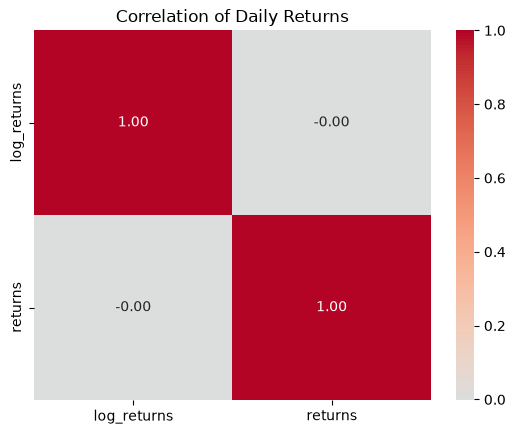

In [19]:
return_cols = [
    "log_returns",
    "returns",
    "DCOILWTICO",
    "sap500",
    "DEXUSEU",
    "DEXJPUS",
    "VIX",
]

return_data = full_df[[c for c in return_cols if c in full_df.columns]].copy()
return_data = return_data.pct_change().dropna()

sns.heatmap(
    return_data.corr(method="pearson"),
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)
plt.title("Correlation of Daily Returns")
plt.show()


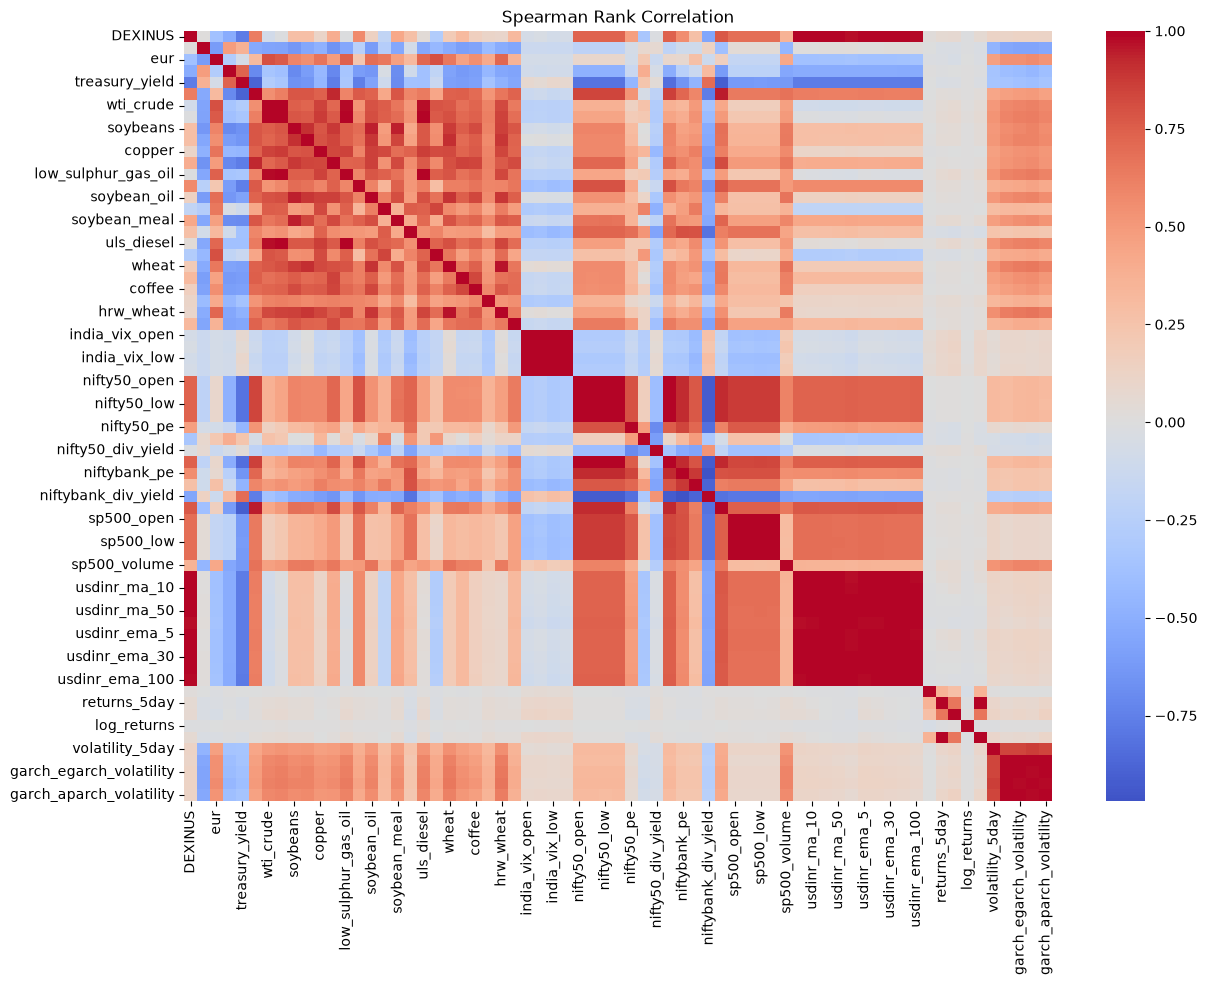

In [20]:
spearman_corr = full_df.corr(method="spearman")

plt.figure(figsize=(14, 10))
sns.heatmap(spearman_corr, cmap="coolwarm", center=0)
plt.title("Spearman Rank Correlation")
plt.show()

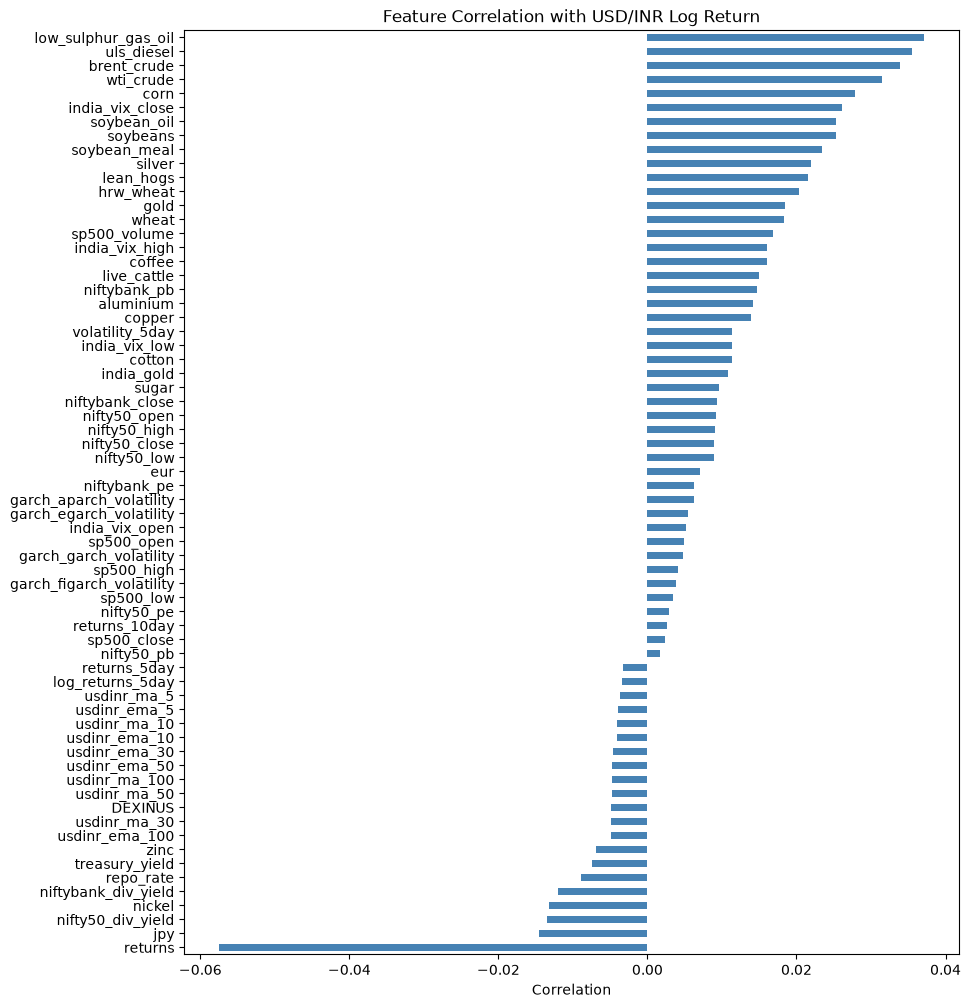

In [21]:
target_corr = (
    full_df.corr()["log_returns"]
    .drop("log_returns")
    .sort_values()
)

target_corr.plot(kind="barh", figsize=(10, 12), color="steelblue")
plt.title("Feature Correlation with USD/INR Log Return")
plt.xlabel("Correlation")
plt.show()

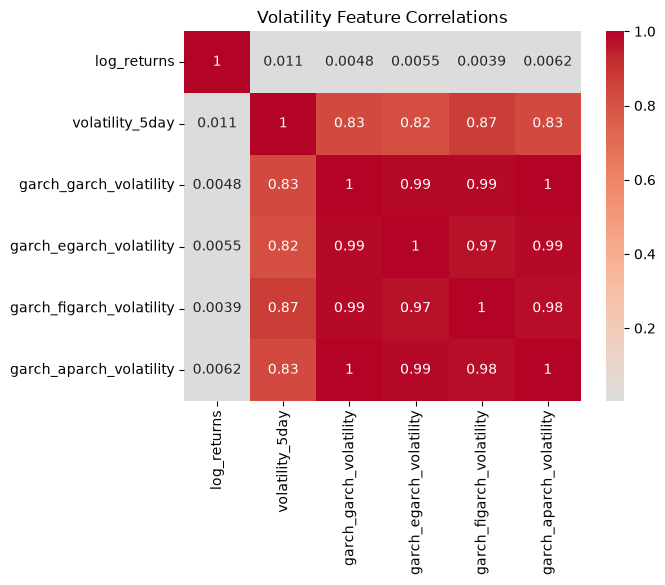

In [22]:
volatility_cols = [
    c for c in full_df.columns
    if "volatility" in c.lower() or "garch" in c.lower()
]

volatility_corr = full_df[
    ["log_returns"] + volatility_cols
].corr()

sns.heatmap(volatility_corr, annot=True, cmap="coolwarm", center=0)
plt.title("Volatility Feature Correlations")
plt.show()

### TRAIN MODEL WITH ALL FEATURES

In [ ]:
features_list = [
    "DEXINUS",
    "jpy",
    "eur",
    "repo_rate",
    "treasury_yield",
    
    # COMMODITY PRICES GLOBALLY
    "gold",
    "wti_crude",
    "brent_crude",
    # "soybeans",
    # "corn",
    "copper",
    "silver",
    # "low_sulphur_gas_oil",
    # "live_cattle",
    # "soybean_oil",
    "aluminium",
    # "soybean_meal",
    "zinc",
    # "uls_diesel",
    "nickel",
    # "wheat",
    # "sugar",
    # "coffee",
    # "lean_hogs",
    # "hrw_wheat",
    # "cotton",
    
    # INDIA DATA
    # "india_vix_open",
    # "india_vix_high",
    # "india_vix_low",
    "india_vix_close",
    # "nifty50_open",
    # "nifty50_high",
    # "nifty50_low",
    "nifty50_close",
    "nifty50_pe",
    "nifty50_pb",
    "nifty50_div_yield",
    "niftybank_close",
    "niftybank_pe",
    "niftybank_pb",
    "niftybank_div_yield",
    "india_gold",
    
    # US DATA
    # "sp500_open",
    # "sp500_high",
    # "sp500_low",
    "sp500_close",
    "sp500_volume",
    
    # Technical Indicators
    "usdinr_ma_5",
    # "usdinr_ma_10",
    "usdinr_ma_30",
    # "usdinr_ma_50",
    # "usdinr_ma_100",
    "usdinr_ema_5",
    # "usdinr_ema_10",
    "usdinr_ema_30",
    # "usdinr_ema_50",
    # "usdinr_ema_100",
    "returns",
    "returns_5day",
    # "returns_10day",
    "log_returns",
    "log_returns_5day",
    "volatility_5day",
    "garch_garch_volatility",
    # "garch_egarch_volatility",
    # "garch_figarch_volatility",
    # "garch_aparch_volatility",
]

### DATALOADERS

In [40]:
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

SEQUENCE_LENGTH = 30
BATCH_SIZE = 64

# Keep the time order intact: train -> validation -> test.
model_df = full_df.sort_index().copy()
features = model_df.loc[:, features_list].astype(np.float32).to_numpy()
targets = model_df.loc[:, target_col].astype(np.float32).to_numpy()

train_end = int(len(model_df) * TRAIN_FRACTION)
validation_end = train_end + int(len(model_df) * VALIDATION_FRACTION)

if train_end <= SEQUENCE_LENGTH or validation_end >= len(model_df):
    raise ValueError("Dataset is too small for the selected split fractions and sequence length.")

feature_scaler = StandardScaler().fit(features[:train_end])
target_scaler = StandardScaler().fit(targets[:train_end, None])
scaled_features = feature_scaler.transform(features).astype(np.float32)
scaled_targets = target_scaler.transform(targets[:, None]).astype(np.float32).ravel()

sequence_values = []
sequence_targets = []
sequence_indices = []
for target_index in range(SEQUENCE_LENGTH, len(model_df)):
    sequence_values.append(scaled_features[target_index - SEQUENCE_LENGTH:target_index])
    sequence_targets.append(scaled_targets[target_index])
    sequence_indices.append(target_index)

sequence_values = torch.tensor(np.asarray(sequence_values), dtype=torch.float32)
sequence_targets = torch.tensor(np.asarray(sequence_targets), dtype=torch.float32).unsqueeze(1)
sequence_indices = np.asarray(sequence_indices)

train_mask = sequence_indices < train_end
validation_mask = (sequence_indices >= train_end) & (sequence_indices < validation_end)
test_mask = sequence_indices >= validation_end

def make_loader(mask, shuffle=False):
    dataset = TensorDataset(sequence_values[mask], sequence_targets[mask])
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, pin_memory=DEVICE.type == "cuda")

train_loader = make_loader(train_mask, shuffle=True)
validation_loader = make_loader(validation_mask)
test_loader = make_loader(test_mask)

print(f"Features: {len(feature_cols)} | Sequence length: {SEQUENCE_LENGTH}")
print(f"Train: {train_mask.sum()} | Validation: {validation_mask.sum()} | Test: {test_mask.sum()}")
print(f"Batch shape: {next(iter(train_loader))[0].shape}")

Features: 66 | Sequence length: 30
Train: 4379 | Validation: 551 | Test: 552
Batch shape: torch.Size([64, 30, 36])


### MODELS

In [ ]:
class LSTMRegressor(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.dl1 = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.dl1(out[:, -1, :])